# Implement a custom pywearable loader

A loader adapts one project or provider to pywearable's canonical
schemas. Domain functions then calculate features without knowing
the original file names or field conventions.

This tutorial builds a small loader from synthetic tables. It
covers:

- the required `BaseLoader` methods;
- capability attributes for optional streams;
- canonical schema preparation and half-open date filtering;
- empty and unsupported streams;
- end-to-end feature extraction and visualization.

## The loader contract

Subclasses implement `get_user_ids`, `load_sleep_summary`,
`load_sleep_stage`, and `load_heart_rate`. Optional methods such as
`load_activity_samples` are implemented only when the source
provides that stream. Capability attributes describe source grain
and available clocks.

Loader methods normalize fields and units. Feature calculations,
aggregation, imputation, and trends remain in the domain modules.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src" / "pywearable").is_dir():
    REPO_ROOT = next(
        parent
        for parent in Path.cwd().resolve().parents
        if (parent / "src" / "pywearable").is_dir()
    )
sys.path.insert(0, str(REPO_ROOT / "src"))

from pywearable import activity, heart_rate, schema, sleep, visualization
from pywearable.loader import BaseLoader

## Create representative source tables

Real adapters would read CSV, Parquet, a database, or an API. These
tables deliberately use source-specific names so the translation
step remains visible.

In [2]:
rng = np.random.default_rng(7)
participant = "participant-01"
start = pd.Timestamp("2026-01-01")
end = pd.Timestamp("2026-01-15")

hr_time = pd.date_range(start, end, freq="5min", inclusive="left")
source_hr = pd.DataFrame(
    {
        "participant": participant,
        "recorded_at": hr_time,
        "bpm": 66
        + 9 * np.sin(2 * np.pi * (hr_time.hour + hr_time.minute / 60) / 24)
        + rng.normal(0, 2.5, len(hr_time)),
    }
)

activity_time = pd.date_range(start, end, freq="15min", inclusive="left")
hour = activity_time.hour.to_numpy()
source_activity = pd.DataFrame(
    {
        "participant": participant,
        "interval_start": activity_time,
        "step_count": rng.poisson(
            2
            + 35 * np.exp(-((hour - 8) / 2.0) ** 2)
            + 50 * np.exp(-((hour - 18) / 2.5) ** 2)
        ),
    }
)

summary_rows = []
stage_rows = []
stages = [("awake", 20), ("light", 90), ("deep", 100), ("light", 80), ("rem", 70), ("light", 90), ("awake", 30)]
for offset, calendar_date in enumerate(pd.date_range(start + pd.Timedelta(days=1), end, inclusive="left")):
    bedtime = calendar_date - pd.Timedelta(days=1) + pd.Timedelta(hours=23, minutes=(offset % 4) * 10)
    summary_id = f"night-{offset + 1}"
    summary_rows.append(
        {
            "night_id": summary_id,
            "sleep_day": calendar_date,
            "bedtime": bedtime,
            "session_end": bedtime + pd.Timedelta(hours=8),
            "sleep_minutes": 430,
            "awake_minutes": 50,
        }
    )
    stage_start = bedtime
    for stage_name, minutes in stages:
        stage_rows.append(
            {
                "night_id": summary_id,
                "stage_start": stage_start,
                "minutes": minutes,
                "stage": stage_name,
            }
        )
        stage_start += pd.Timedelta(minutes=minutes)

source_sleep = pd.DataFrame(summary_rows)
source_stages = pd.DataFrame(stage_rows)
display(source_hr.head(2), source_activity.head(2), source_sleep.head(2), source_stages.head(2))

,participant,recorded_at,bpm
0,participant-01,2026-01-01 00:00:00,66.003075
1,participant-01,2026-01-01 00:05:00,66.943198


,participant,interval_start,step_count
0,participant-01,2026-01-01 00:00:00,3
1,participant-01,2026-01-01 00:15:00,0


,night_id,sleep_day,bedtime,session_end,sleep_minutes,awake_minutes
0,night-1,2026-01-02,2026-01-01 23:00:00,2026-01-02 07:00:00,430,50
1,night-2,2026-01-03,2026-01-02 23:10:00,2026-01-03 07:10:00,430,50


,night_id,stage_start,minutes,stage
0,night-1,2026-01-01 23:00:00,20,awake
1,night-1,2026-01-01 23:20:00,90,light


## Implement the adapter

Each method returns canonical columns and applies `[start_date,
end_date)` to the clock documented by that method. Schema preparers
normalize types, add optional columns, and validate required fields.
Returning a typed empty canonical frame is preferable to inventing
observations when a supported interval has no rows.

In [3]:
class SyntheticLoader(BaseLoader):
    activity_source = "samples"
    activity_primary_resolution = "15min"
    activity_time_columns = (schema.UTC_TIME_COL, schema.LOCAL_TIME_COL)
    heart_rate_time_columns = (schema.UTC_TIME_COL, schema.LOCAL_TIME_COL)

    def __init__(self, heart_rate_rows, activity_rows, sleep_rows, stage_rows):
        self._heart_rate = heart_rate_rows.copy()
        self._activity = activity_rows.copy()
        self._sleep = sleep_rows.copy()
        self._stages = stage_rows.copy()

    def get_user_ids(self):
        return sorted(self._heart_rate["participant"].unique())

    @staticmethod
    def _filter(frame, column, start_date, end_date):
        values = pd.to_datetime(frame[column])
        mask = pd.Series(True, index=frame.index)
        if start_date is not None:
            mask &= values >= pd.Timestamp(start_date)
        if end_date is not None:
            mask &= values < pd.Timestamp(end_date)
        return frame.loc[mask].copy()

    def load_heart_rate(self, user_id, start_date=None, end_date=None, time_col="local_time"):
        rows = self._heart_rate[self._heart_rate["participant"].eq(user_id)].copy()
        canonical = pd.DataFrame(
            {
                schema.UTC_TIME_COL: rows["recorded_at"],
                schema.LOCAL_TIME_COL: rows["recorded_at"],
                schema.TIMEZONE_COL: pd.Timedelta(0),
                schema.HEART_RATE_COL: rows["bpm"],
            }
        )
        canonical = schema.prepare_heart_rate_samples(canonical)
        return self._filter(canonical, time_col, start_date, end_date)

    def load_activity_samples(self, user_id, start_date=None, end_date=None, **kwargs):
        rows = self._activity[self._activity["participant"].eq(user_id)].copy()
        canonical = pd.DataFrame(
            {
                schema.UTC_TIME_COL: rows["interval_start"],
                schema.LOCAL_TIME_COL: rows["interval_start"],
                schema.TIMEZONE_COL: pd.Timedelta(0),
                schema.DURATION_IN_MS_COL: 15 * 60_000,
                schema.ACTIVITY_STEPS_COL: rows["step_count"],
            }
        )
        canonical = schema.prepare_activity_samples(canonical)
        return self._filter(
            canonical, schema.LOCAL_TIME_COL, start_date, end_date
        )

    def load_sleep_summary(self, user_id, start_date=None, end_date=None, drop_duplicates=True):
        rows = self._sleep.copy()
        canonical = pd.DataFrame(
            {
                schema.SLEEP_SUMMARY_ID_COL: rows["night_id"],
                schema.CALENDAR_DATE_COL: rows["sleep_day"],
                schema.LOCAL_TIME_COL: rows["bedtime"],
                schema.LOCAL_END_TIME_COL: rows["session_end"],
                schema.DURATION_IN_MS_COL: rows["sleep_minutes"] * 60_000,
                schema.SLEEP_SUMMARY_AWAKE_DURATION_IN_MS_COL: rows["awake_minutes"] * 60_000,
            }
        )
        canonical = schema.prepare_sleep_summary(canonical)
        canonical = self._filter(
            canonical, schema.CALENDAR_DATE_COL, start_date, end_date
        )
        if drop_duplicates:
            canonical = canonical.drop_duplicates(schema.CALENDAR_DATE_COL)
        return canonical.reset_index(drop=True)

    def load_sleep_stage(self, user_id, start_date=None, end_date=None):
        rows = self._stages.copy()
        canonical = pd.DataFrame(
            {
                schema.SLEEP_SUMMARY_ID_COL: rows["night_id"],
                schema.LOCAL_TIME_COL: rows["stage_start"],
                schema.DURATION_IN_MS_COL: rows["minutes"] * 60_000,
                schema.SLEEP_STAGE_SLEEP_TYPE_COL: rows["stage"],
            }
        )
        canonical = schema.prepare_sleep_stages(canonical)
        stage_end = canonical[schema.LOCAL_TIME_COL] + pd.to_timedelta(
            canonical[schema.DURATION_IN_MS_COL], unit="ms"
        )
        mask = pd.Series(True, index=canonical.index)
        if start_date is not None:
            mask &= stage_end > pd.Timestamp(start_date)
        if end_date is not None:
            mask &= canonical[schema.LOCAL_TIME_COL] < pd.Timestamp(end_date)
        return canonical.loc[mask].reset_index(drop=True)


loader = SyntheticLoader(source_hr, source_activity, source_sleep, source_stages)
print(loader.get_user_ids())

['participant-01']


## Validate the canonical boundary

Before using domain functions, inspect each loader method directly.
Required columns, dtypes, sorting, duplicate handling, and empty
intervals are part of the loader contract.

In [4]:
hr = loader.load_heart_rate(participant, start, start + pd.Timedelta(hours=1))
activity_samples = loader.load_activity_samples(participant, start, start + pd.Timedelta(hours=1))
summaries = loader.load_sleep_summary(participant, start, end)
stage_intervals = loader.load_sleep_stage(participant, start, end)

assert set(schema.HEART_RATE_REQUIRED_COLUMNS) <= set(hr)
assert set(schema.ACTIVITY_SAMPLE_REQUIRED_COLUMNS) <= set(activity_samples)
assert set(schema.SLEEP_SUMMARY_REQUIRED_COLUMNS) <= set(summaries)
assert tuple(stage_intervals.columns) == schema.SLEEP_STAGE_REQUIRED_COLUMNS
assert loader.load_heart_rate(participant, end, end + pd.Timedelta(days=1)).empty
print("Canonical loader checks passed")

Canonical loader checks passed


## Use the normal pywearable APIs

Once the adapter returns canonical streams, no project-specific
code is needed for feature extraction.

In [5]:
daily_steps = activity.get_activity_statistics(
    loader,
    statistic=activity.ACTIVITY_STATISTIC_STEPS,
    user_id=participant,
    start_date=start,
    end_date=end,
    resolution="daily",
)
daily_hr = heart_rate.get_heart_rate_statistics(
    loader,
    statistic=[
        heart_rate.HEART_RATE_STATISTIC_MEAN,
        heart_rate.HEART_RATE_STATISTIC_REST,
    ],
    user_id=participant,
    start_date=start,
    end_date=end,
    resolution="daily",
)
nightly_sleep = sleep.get_sleep_statistics(
    loader,
    statistic=[
        sleep.SLEEP_STATISTIC_TIB,
        sleep.SLEEP_STATISTIC_TST,
        sleep.SLEEP_STATISTIC_WASO,
        sleep.SLEEP_STATISTIC_BEDTIME,
    ],
    user_id=participant,
    start_date=start,
    end_date=end,
    resolution="nightly",
)
display(daily_steps.head(), daily_hr.head(), nightly_sleep.head())

activity_steps  activity_steps__coverage
user_id        calendar_date                                          
participant-01 2026-01-01             1498.0                  0.975000
               2026-01-02             1603.0                  0.975000
               2026-01-03             1574.0                  0.966667
               2026-01-04             1491.0                  0.950000
               2026-01-05             1601.0                  0.933333

heart_rate_mean  heart_rate_mean__coverage  \
user_id        local_time                                               
participant-01 2026-01-01        65.645475                        1.0   
               2026-01-02        65.630113                        1.0   
               2026-01-03        65.932339                        1.0   
               2026-01-04        66.074904                        1.0   
               2026-01-05        66.004249                        1.0   

                           heart_rate_rest  heart_rate_rest__coverage  
user_id        local_time                                              
participant-01 2026-01-01              NaN                        1.0  
               2026-01-02              NaN                        1.0  
               2026-01-03              NaN                        1.0  
               2026-01-04              NaN                        1.0  
               2026-01-05              NaN                        1.0

sleep_TIB  sleep_TIB__coverage  sleep_TST  \
user_id        calendar_date                                              
participant-01 2026-01-01           NaN                  0.0        NaN   
               2026-01-02         480.0                  1.0        NaN   
               2026-01-03         480.0                  1.0        NaN   
               2026-01-04         480.0                  1.0        NaN   
               2026-01-05         480.0                  1.0        NaN   

                              sleep_TST__coverage  sleep_WASO  \
user_id        calendar_date                                    
participant-01 2026-01-01                     0.0         NaN   
               2026-01-02                     0.0         0.0   
               2026-01-03                     0.0         0.0   
               2026-01-04                     0.0         0.0   
               2026-01-05                     0.0         0.0   

                              sleep_WASO__coverage       sleep_bedtime  \
user_id        calendar_date                                             
participant-01 2026-01-01                      0.0                 NaT   
               2026-01-02                      1.0 2026-01-01 23:00:00   
               2026-01-03                      1.0 2026-01-02 23:10:00   
               2026-01-04                      1.0 2026-01-03 23:20:00   
               2026-01-05                      1.0 2026-01-04 23:30:00   

                              sleep_bedtime__coverage  
user_id        calendar_date                           
participant-01 2026-01-01                         0.0  
               2026-01-02                         1.0  
               2026-01-03                         1.0  
               2026-01-04                         1.0  
               2026-01-05                         1.0

## Verify a composite view

The weekly overview needs timestamped activity samples, heart rate,
and sleep stages. Implementing those three streams makes the
loader-aware visualization available automatically.

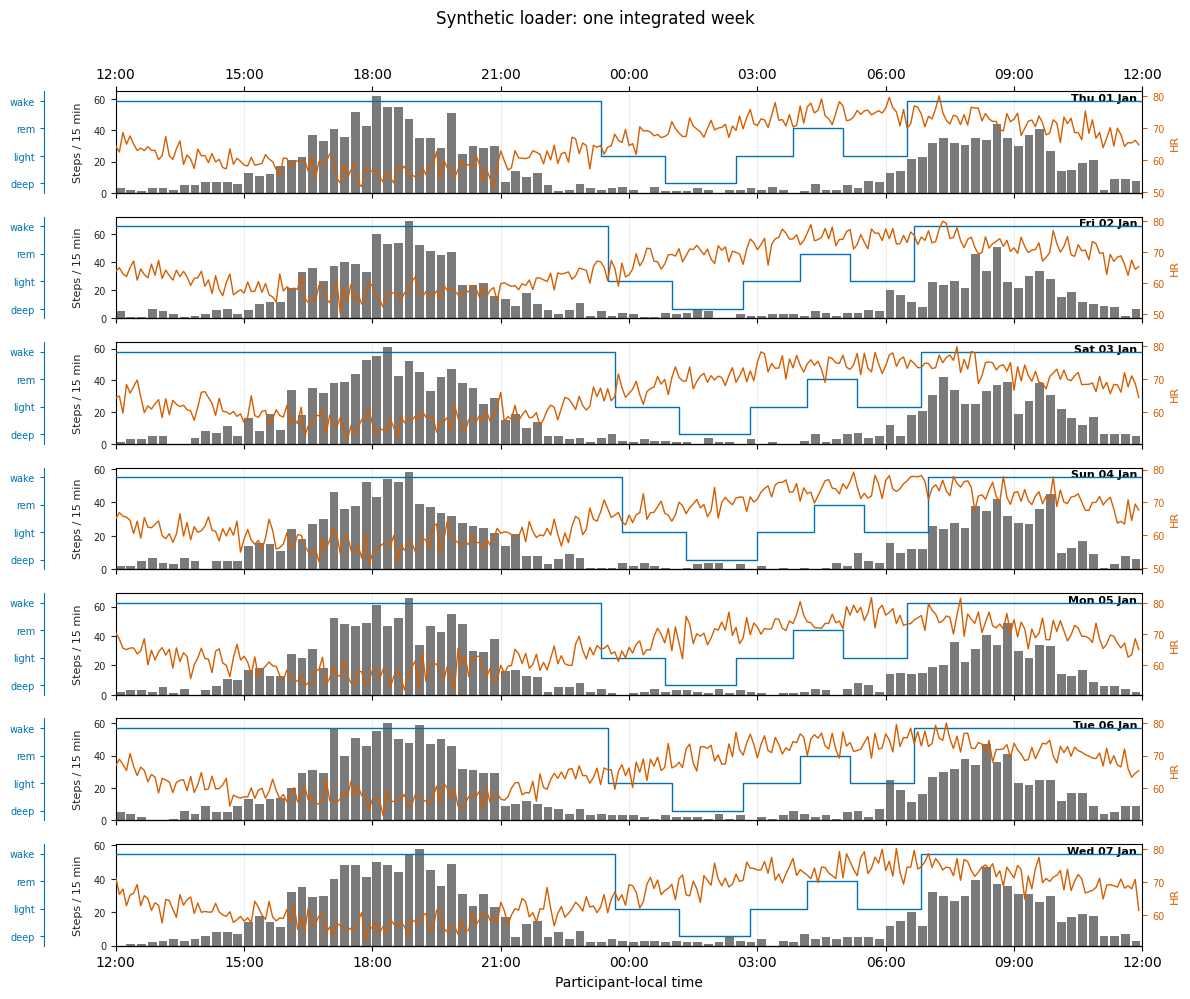

In [6]:
visualization.plot_weekly_overview(
    loader,
    participant,
    start,
    start + pd.Timedelta(days=7),
    title="Synthetic loader: one integrated week",
    show=False,
)
plt.show()

## Exercise

Add an optional provider-native daily score.

1. Add its name to `provider_features`.
2. Implement `load_provider_feature` with a daily canonical table.
3. Call `provider_features.get_available_provider_features` and
   `provider_features.get_provider_features`.
4. Add tests for empty bounds and an unknown feature name.

In [7]:
# Suggested scaffold:
# class ExtendedSyntheticLoader(SyntheticLoader):
#     provider_features = frozenset({"my_provider_score"})
#
#     def load_provider_feature(self, feature, user_id, start_date=None, end_date=None):
#         ...

## Production checklist

- Preserve the provider's native resolution and units.
- Expose UTC and local clocks only when they are known.
- Apply `[start_date, end_date)` consistently.
- Keep observed zero distinct from missing data.
- Return canonical empty frames for supported but empty intervals.
- Raise a clear error for unsupported provider-native features.
- Link every sleep-stage interval to a `sleep_summary_id`.
- Test duplicate records, timezone changes, empty intervals, and
  one end-to-end domain function for every implemented stream.